In [4]:
1+4

5

In [6]:
"""
ジェット追跡 修正版：候補図を先に表示し、番号を選んでからJet 1/2を結ぶ。

上から順に実行する。候補図とCSVは手順1、経路の図とCSVは手順3で保存される。
同じ観測日のIMAPの理論noiseを画素面積で換算し、10σ以上の局所ピークを選ぶ。
"""

'\nジェット追跡 修正版：候補図を先に表示し、番号を選んでからJet 1/2を結ぶ。\n\n上から順に実行する。候補図とCSVは手順1、経路の図とCSVは手順3で保存される。\n同じ観測日のIMAPの理論noiseを画素面積で換算し、10σ以上の局所ピークを選ぶ。クリック操作は不要。\n'

In [8]:
# ============================================================
# 使用するライブラリ
# ============================================================
from pathlib import Path
import csv
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits
from scipy.ndimage import gaussian_filter, maximum_filter
from IPython.display import Image, display


In [140]:
# ============================================================
# 入力FITS・保存先・候補点抽出の設定
# FITS_FILEとOUTPUT_DIRは自分の環境に合わせて変更する
# ============================================================
FITS_FILE = Path("/Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/fits/1652+398Q.2023-05-21_mimg.fits")
IMAP_FILE = Path("/Users/reiya/Desktop/imaging/I-map_fits/1652+398Q.2023-05-21.IMAP")
OUTPUT_DIR = Path("/Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/jet_tracking_2")

# CD行列・CDELTを含まないFITSを使う場合だけ、FOVをmasで指定する。
# 通常はNoneのままでよい。指定する場合は画像とピクセルが正方形であることを想定。
FALLBACK_FOV_MAS = None
# 画素スケールがFITSにない場合用：+1はxが増える方向が東、-1は西。
FALLBACK_X_EAST_SIGN = -1
DISPLAY_LOG = True           # 保存する画像をlog色スケールで表示
CORE_EXCLUSION_PIXELS = 3
SMOOTH_SIGMA_PIXELS = 0.5   # ピーク判定時だけ平滑化。出力の輝度は元データ
LOCAL_MAX_SIZE = 3          # 局所最大を探す窓（奇数）
MIN_SEPARATION_PIXELS = 2   # 候補点同士の最小距離
DETECTION_SIGMA = 20    # 元画像の画素値が換算したnoiseの何倍以上か/値わざと大きくして理論よりも大きく 20~
N_CANDIDATES = 20          # 画像全体から表示する候補点の最大数


In [142]:
# ============================================================
# FITSから2次元の輝度画像とヘッダーを読み込む
# ============================================================
def load_map(path):
    with fits.open(path) as hdul:
        hdu = next((h for h in hdul if h.data is not None), None)
        if hdu is None:
            raise ValueError(f"No image data in {path}")
        header = hdu.header.copy()
        raw = np.asarray(hdu.data, dtype=float)
    image = np.squeeze(raw)
    if image.ndim != 2:
        raise ValueError(f"Expected a 2D image after squeeze, got {raw.shape}: {path}")
    if not np.isfinite(image).any():
        raise ValueError(f"No finite image pixels: {path}")
    return image, header

# ============================================================
# 同じ観測日のIMAPのNOISEをComrade画像のmJy/pixelへ面積換算
# ============================================================
def noise_per_pixel_mjy(imap_path, mimg_path, mimg_header, image_shape):
    """Jy/beamの理論RMSを、画素面積/ビーム面積でmJy/pixelに換算。

    Comradeの事後画像の統計誤差とは異なるので、候補抽出の目安として使用する。
    """
    if not imap_path.is_file():
        raise FileNotFoundError(f"同じ観測日のIMAPを指定してください: {imap_path}")
    image_date = re.search(r"\d{4}-\d{2}-\d{2}", mimg_path.name)
    imap_date = re.search(r"\d{4}-\d{2}-\d{2}", imap_path.name)
    if image_date is None or imap_date is None or image_date.group() != imap_date.group():
        raise ValueError("IMAP_FILEとFITS_FILEのファイル名の観測日を揃えてください")
    with fits.open(imap_path) as hdul:
        imap_header = hdul[0].header
        if str(imap_header.get("BUNIT", "")).strip().lower() != "jy/beam":
            raise ValueError("IMAPのBUNITがJy/beamではありません。単位を確認してください")
        values = [imap_header.get(key) for key in ("NOISE", "BMAJ", "BMIN")]
    if any(value is None for value in values):
        raise ValueError("IMAPヘッダーにNOISE、BMAJ、BMINが必要です")
    noise_jy_beam, bmaj_deg, bmin_deg = map(float, values)
    if not all(np.isfinite(v) and v > 0 for v in values):
        raise ValueError("IMAPのNOISE、BMAJ、BMINは正の有限値にしてください")
    # (x, y)方向に1画素進んだときの東・北への角度[mas]から画素面積を求める。
    east, north, _ = coordinates_mas([(1, 0), (0, 1)], (0, 0), mimg_header, image_shape)
    pixel_area_mas2 = abs(east[0] * north[1] - east[1] * north[0])
    beam_area_mas2 = np.pi * (bmaj_deg * 3_600_000) * (bmin_deg * 3_600_000) / (4 * np.log(2))
    pixels_per_beam = beam_area_mas2 / pixel_area_mas2
    noise_mjy_pixel = noise_jy_beam * 1000 / pixels_per_beam
    print(f"IMAP理論RMS: {noise_jy_beam * 1000:.5g} mJy/beam")
    print(f"ビーム面積: {pixels_per_beam:.3f} 画素 / beam")
    print(f"画素面積換算: {noise_mjy_pixel:.5g} mJy/pixel")
    print(f"候補の下限: {DETECTION_SIGMA * noise_mjy_pixel:.5g} mJy/pixel ({DETECTION_SIGMA:g}倍)")
    return noise_mjy_pixel


In [144]:
# ============================================================
# 画像全体から局所的な輝度ピークを候補として抽出
# ============================================================
def find_candidates(image, core, noise_mjy_pixel):
    """平滑化画像で局所ピークを探し、元画像の画素値で5σ判定する。"""
    if LOCAL_MAX_SIZE < 3 or LOCAL_MAX_SIZE % 2 != 1:
        raise ValueError("LOCAL_MAX_SIZEは3以上の奇数にしてください")
    clean = np.where(np.isfinite(image), image, 0.0)
    smooth = gaussian_filter(clean, SMOOTH_SIGMA_PIXELS)
    yy, xx = np.indices(image.shape)
    mask = ((smooth == maximum_filter(smooth, size=LOCAL_MAX_SIZE)) &
            (image >= DETECTION_SIGMA * noise_mjy_pixel) &
            np.isfinite(image) &
            ((xx - core[0]) ** 2 + (yy - core[1]) ** 2 >= CORE_EXCLUSION_PIXELS ** 2))
    ys, xs = np.where(mask)
    ranked = sorted(zip(xs, ys), key=lambda p: (-smooth[p[1], p[0]], p[1], p[0]))
    kept = []
    for x, y in ranked:
        if all(np.hypot(x - q[0], y - q[1]) >= MIN_SEPARATION_PIXELS for q in kept):
            kept.append((int(x), int(y)))
        if len(kept) >= N_CANDIDATES:
            break
    return {i: p for i, p in enumerate(kept, start=1)}

In [146]:
# ============================================================
# FITSヘッダーの画素スケールを使ってコアからの相対位置をmasに変換
# ============================================================
def coordinates_mas(points, core, header, shape):
    """コアからの東西・南北方向のずれをmas単位で返す。"""
    x = np.array([p[0] for p in points], dtype=float)
    y = np.array([p[1] for p in points], dtype=float)
    dx, dy = x - core[0], y - core[1]

    # 添付FITSはRA---SIN/DEC---SINとCD行列を持つが、CRVAL1/2はない。
    # コアからの相対位置にはCRVALやCRPIXは不要。CDの差分だけをmasに直す。
    ra_dec = (str(header.get("CTYPE1", "")).startswith("RA") and
              str(header.get("CTYPE2", "")).startswith("DEC"))
    if ra_dec and all(k in header for k in ("CD1_1", "CD1_2", "CD2_1", "CD2_2")):
        cd = np.array([[header["CD1_1"], header["CD1_2"]],
                       [header["CD2_1"], header["CD2_2"]]], dtype=float)
        source = "FITS CD matrix"
    elif ra_dec and all(k in header for k in ("CDELT1", "CDELT2")):
        pc = np.array([[header.get("PC1_1", 1.0), header.get("PC1_2", 0.0)],
                       [header.get("PC2_1", 0.0), header.get("PC2_2", 1.0)]], dtype=float)
        cd = np.diag([float(header["CDELT1"]), float(header["CDELT2"])]) @ pc
        source = "FITS CDELT/PC"
    else:
        cd = None

    if cd is not None:
        if not np.all(np.isfinite(cd)) or abs(np.linalg.det(cd)) < 1e-30:
            raise ValueError("FITSの画素スケールが無効です。CD/CDELTを確認してください")
        # CUNITが省略されているFITSでは、FITS標準どおりdegとして扱う。
        units = [str(header.get(k, "deg")).strip().lower() for k in ("CUNIT1", "CUNIT2")]
        factors = {"deg": 3_600_000.0, "degree": 3_600_000.0,
                   "rad": 180.0 / np.pi * 3_600_000.0,
                   "mas": 1.0, "arcsec": 1_000.0}
        if any(u not in factors for u in units):
            raise ValueError(f"未対応のFITS角度単位です: {units}")
        east = (cd[0, 0] * dx + cd[0, 1] * dy) * factors[units[0]]
        north = (cd[1, 0] * dx + cd[1, 1] * dy) * factors[units[1]]
        return east, north, source

    if FALLBACK_FOV_MAS is None or FALLBACK_FOV_MAS <= 0 or shape[0] != shape[1]:
        raise ValueError("FITSに画素スケールがありません。FALLBACK_FOV_MASを指定してください")
    step = FALLBACK_FOV_MAS / shape[1]
    return dx * step * FALLBACK_X_EAST_SIGN, dy * step, "FOV fallback"


In [148]:
# ============================================================
# 東西・南北方向のずれから位置角（PA）を計算
# ============================================================
def pa_deg(east, north):
    """位置角を返す。北が0°、東が90°で、天球上で時計回りに測る。"""
    return float(np.degrees(np.arctan2(east, north)) % 360.0)

In [150]:
# ============================================================
# 候補点と経路の図を保存するための背景画像を作る
# ============================================================
def make_figure(image, unit):
    finite = image[np.isfinite(image)]
    hi = float(np.max(finite))
    fig, ax = plt.subplots(figsize=(9, 8))
    if DISPLAY_LOG and hi > 0 and np.any(finite < hi):
        positive = finite[finite > 0]
        lo = max(float(np.min(positive)), hi * 1e-5)
        if lo < hi:
            im = ax.imshow(image, origin="lower", cmap="inferno", norm=LogNorm(vmin=lo, vmax=hi))
        else:
            im = ax.imshow(image, origin="lower", cmap="inferno", vmin=0, vmax=hi)
    else:
        lo = float(np.min(finite))
        im = ax.imshow(image, origin="lower", cmap="inferno", vmin=lo, vmax=hi)
    fig.colorbar(im, ax=ax, label=unit)
    ax.set(xlabel="FITS x pixel", ylabel="FITS y pixel")
    fig.tight_layout()
    return fig, ax

In [152]:
# ============================================================
# 候補点一覧を画像とCSVに保存し、指定番号だけを経路として結ぶ
# ============================================================
def process(path, mode):
    image, header = load_map(path)
    date_match = re.search(r"\d{4}-\d{2}-\d{2}", path.name)
    if date_match is None:
        raise ValueError(f"FITSのファイル名から観測日を読み取れません: {path.name}")
    observation_date = date_match.group()
    input_unit = str(header.get("BUNIT", "")).strip()
    # 添付FITSのJy/pixelをmJy/pixelへ換算（値は1000倍）。
    if input_unit.lower() == "jy/pixel":
        image = image * 1000.0
        unit = "mJy/pixel"
    elif input_unit == "mJy/pixel":
        unit = input_unit
    else:
        raise ValueError(f"想定外の輝度単位です: {input_unit!r}。BUNITを確認してください")
    core_index = np.argmax(np.where(np.isfinite(image), image, -np.inf))
    core_y, core_x = np.unravel_index(core_index, image.shape)
    core = (int(core_x), int(core_y))
    noise_mjy_pixel = noise_per_pixel_mjy(IMAP_FILE, path, header, image.shape)
    candidates = find_candidates(image, core, noise_mjy_pixel)
    if not candidates:
        print("5σ以上の候補はありません。IMAPのnoise・ビーム・観測日を確認してください")
    points = list(candidates.values())
    east, north, source = coordinates_mas(points, core, header, image.shape)

    if mode not in {"candidates", "selected"}:
        raise ValueError("modeは'candidates'または'selected'にしてください")
    if mode == "candidates":
        fig, ax = make_figure(image, unit)
        ax.scatter(*core, marker="x", s=130, c="white", linewidths=2, label="Core")
        ax.annotate("Core", core, xytext=(7, 7), textcoords="offset points", color="white")
        candidate_dir = OUTPUT_DIR / "01_brightness_candidates"
        candidate_dir.mkdir(parents=True, exist_ok=True)
        candidate_csv = candidate_dir / f"{observation_date}.csv"
        with candidate_csv.open("w", newline="", encoding="utf-8-sig") as f:
            w = csv.writer(f)
            w.writerow(["epoch_file", "candidate_id", "pixel_x", "pixel_y", "peak_brightness_mJy_per_pixel",
                        "brightness_unit", "east_mas", "north_mas", "core_distance_mas",
                        "core_PA_deg", "coordinate_source", "noise_mJy_per_pixel", "peak_SNR"])
            for idx, (x, y) in candidates.items():
                e, n = float(east[idx - 1]), float(north[idx - 1])
                w.writerow([path.name, idx, x, y, image[y, x], unit, e, n,
                            np.hypot(e, n), pa_deg(e, n), source, noise_mjy_pixel, image[y, x] / noise_mjy_pixel])
                ax.scatter(x, y, c="cyan", s=35, edgecolors="black", zorder=4)
                ax.annotate(f"{idx}", (x, y), xytext=(5, 5), textcoords="offset points",
                            color="white", fontsize=9, weight="bold")
                print(f"候補{idx:2d}: pixel=({x:2d},{y:2d}) "
                      f"I={image[y, x]:.5g} {unit}, I/noise={image[y, x] / noise_mjy_pixel:.2f}, "
                      f"(東,北)=({e:+.3f},{n:+.3f}) mas")
        ax.set_title(f"{path.name} | brightness candidates")
        ax.legend(loc="upper right")
        candidate_png = OUTPUT_DIR / f"{observation_date}_candidate_numbers.png"
        fig.savefig(candidate_png, dpi=200, bbox_inches="tight")
        plt.close(fig)
        if not candidate_png.is_file():
            raise RuntimeError(f"候補図を保存できませんでした: {candidate_png}")
        print(f"候補図を保存: {candidate_png.resolve()}")
        print(f"候補CSVを保存: {candidate_csv.resolve()}")
        display(Image(filename=str(candidate_png), width=700))

        return

    selections = {"Jet 1": JET1_IDS, "Jet 2": JET2_IDS}
    for jet, ids in selections.items():
        if len(ids) != len(set(ids)) or any(i not in candidates for i in ids):
            raise ValueError(f"{jet}の番号が重複、または候補一覧に存在しません: {ids}")
    if not any(selections.values()):
        raise ValueError("先に候補図を見てJET1_IDS / JET2_IDSへ番号を入力してください")

    fig, ax = make_figure(image, unit)
    ax.scatter(*core, marker="x", s=130, c="white", linewidths=2, label="Core")
    colors = {"Jet 1": "cyan", "Jet 2": "lime"}
    points_dir = OUTPUT_DIR / "02_selected_jet_points"
    segments_dir = OUTPUT_DIR / "03_jet_segment_angles"
    points_dir.mkdir(parents=True, exist_ok=True)
    segments_dir.mkdir(parents=True, exist_ok=True)
    points_csv = points_dir / f"{observation_date}.csv"
    segments_csv = segments_dir / f"{observation_date}.csv"
    with points_csv.open("w", newline="", encoding="utf-8-sig") as fp, \
         segments_csv.open("w", newline="", encoding="utf-8-sig") as fs:
        wp, ws = csv.writer(fp), csv.writer(fs)
        wp.writerow(["epoch_file", "jet", "order", "candidate_id", "pixel_x", "pixel_y",
                     "peak_brightness_mJy_per_pixel", "brightness_unit", "east_mas", "north_mas",
                     "core_distance_mas", "core_PA_deg", "coordinate_source", "noise_mJy_per_pixel", "peak_SNR"])
        ws.writerow(["epoch_file", "jet", "from_id", "to_id", "length_mas",
                     "PA_deg", "delta_east_mas", "delta_north_mas"])
        for jet, ids in selections.items():
            if not ids:
                continue
            color = colors[jet]
            coords = [core] + [candidates[i] for i in ids]
            ax.plot([p[0] for p in coords], [p[1] for p in coords], "-o",
                    color=color, linewidth=1.5, markersize=5, label=jet)
            previous_e, previous_n, previous_label = 0.0, 0.0, "Core"
            for k, cid in enumerate(ids, start=1):
                x, y = candidates[cid]
                e, n = float(east[cid - 1]), float(north[cid - 1])
                de, dn = e - previous_e, n - previous_n
                segment_pa = pa_deg(de, dn)
                wp.writerow([path.name, jet, k, cid, x, y, image[y, x], unit,
                             e, n, np.hypot(e, n), pa_deg(e, n), source, noise_mjy_pixel, image[y, x] / noise_mjy_pixel])
                ws.writerow([path.name, jet, previous_label, cid, np.hypot(de, dn),
                             segment_pa, de, dn])
                previous_e, previous_n, previous_label = e, n, cid
    ax.set_title(f"{path.name} | selected Jet 1 / Jet 2")
    ax.legend(loc="upper right")
    jet_png = OUTPUT_DIR / f"{observation_date}_jet_lines_no_numbers.png"
    fig.savefig(jet_png, dpi=200, bbox_inches="tight")
    plt.close(fig)
    for saved in (jet_png, points_csv, segments_csv):
        if not saved.is_file():
            raise RuntimeError(f"出力を保存できませんでした: {saved}")
        print(f"保存: {saved.resolve()}")
    display(Image(filename=str(jet_png), width=700))


In [154]:
# ============================================================
# FITSの確認・保存先の作成・指定された処理の実行
# ============================================================
def main(mode):
    if not IMAP_FILE.is_file():
        raise FileNotFoundError(f"IMAP file not found: {IMAP_FILE}")
    if not FITS_FILE.is_file():
        raise FileNotFoundError(f"FITS file not found: {FITS_FILE}")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    process(FITS_FILE, mode=mode)
    print(f"保存先フォルダ: {OUTPUT_DIR.resolve()}")


IMAP理論RMS: 0.42712 mJy/beam
ビーム面積: 57.434 画素 / beam
画素面積換算: 0.0074366 mJy/pixel
候補の下限: 0.14873 mJy/pixel (20倍)
候補 1: pixel=(54,49) I=10.139 mJy/pixel, I/noise=1363.32, (東,北)=(-0.125,-0.031) mas
候補 2: pixel=(55,52) I=6.2338 mJy/pixel, I/noise=838.26, (東,北)=(-0.156,+0.062) mas
候補 3: pixel=(52,55) I=3.4769 mJy/pixel, I/noise=467.53, (東,北)=(-0.062,+0.156) mas
候補 4: pixel=(47,55) I=1.9433 mJy/pixel, I/noise=261.31, (東,北)=(+0.094,+0.156) mas
候補 5: pixel=(41,52) I=0.65091 mJy/pixel, I/noise=87.53, (東,北)=(+0.281,+0.062) mas
候補 6: pixel=(35,49) I=0.53747 mJy/pixel, I/noise=72.27, (東,北)=(+0.469,-0.031) mas
候補 7: pixel=(43,42) I=0.40919 mJy/pixel, I/noise=55.02, (東,北)=(+0.219,-0.250) mas
候補 8: pixel=(38,33) I=0.39375 mJy/pixel, I/noise=52.95, (東,北)=(+0.375,-0.531) mas
候補 9: pixel=(30,45) I=0.26557 mJy/pixel, I/noise=35.71, (東,北)=(+0.625,-0.156) mas
候補図を保存: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/jet_tracking_2/2023-05-21_candidate_numbers.png
候補CSVを保存: /Users/reiya/Desktop/

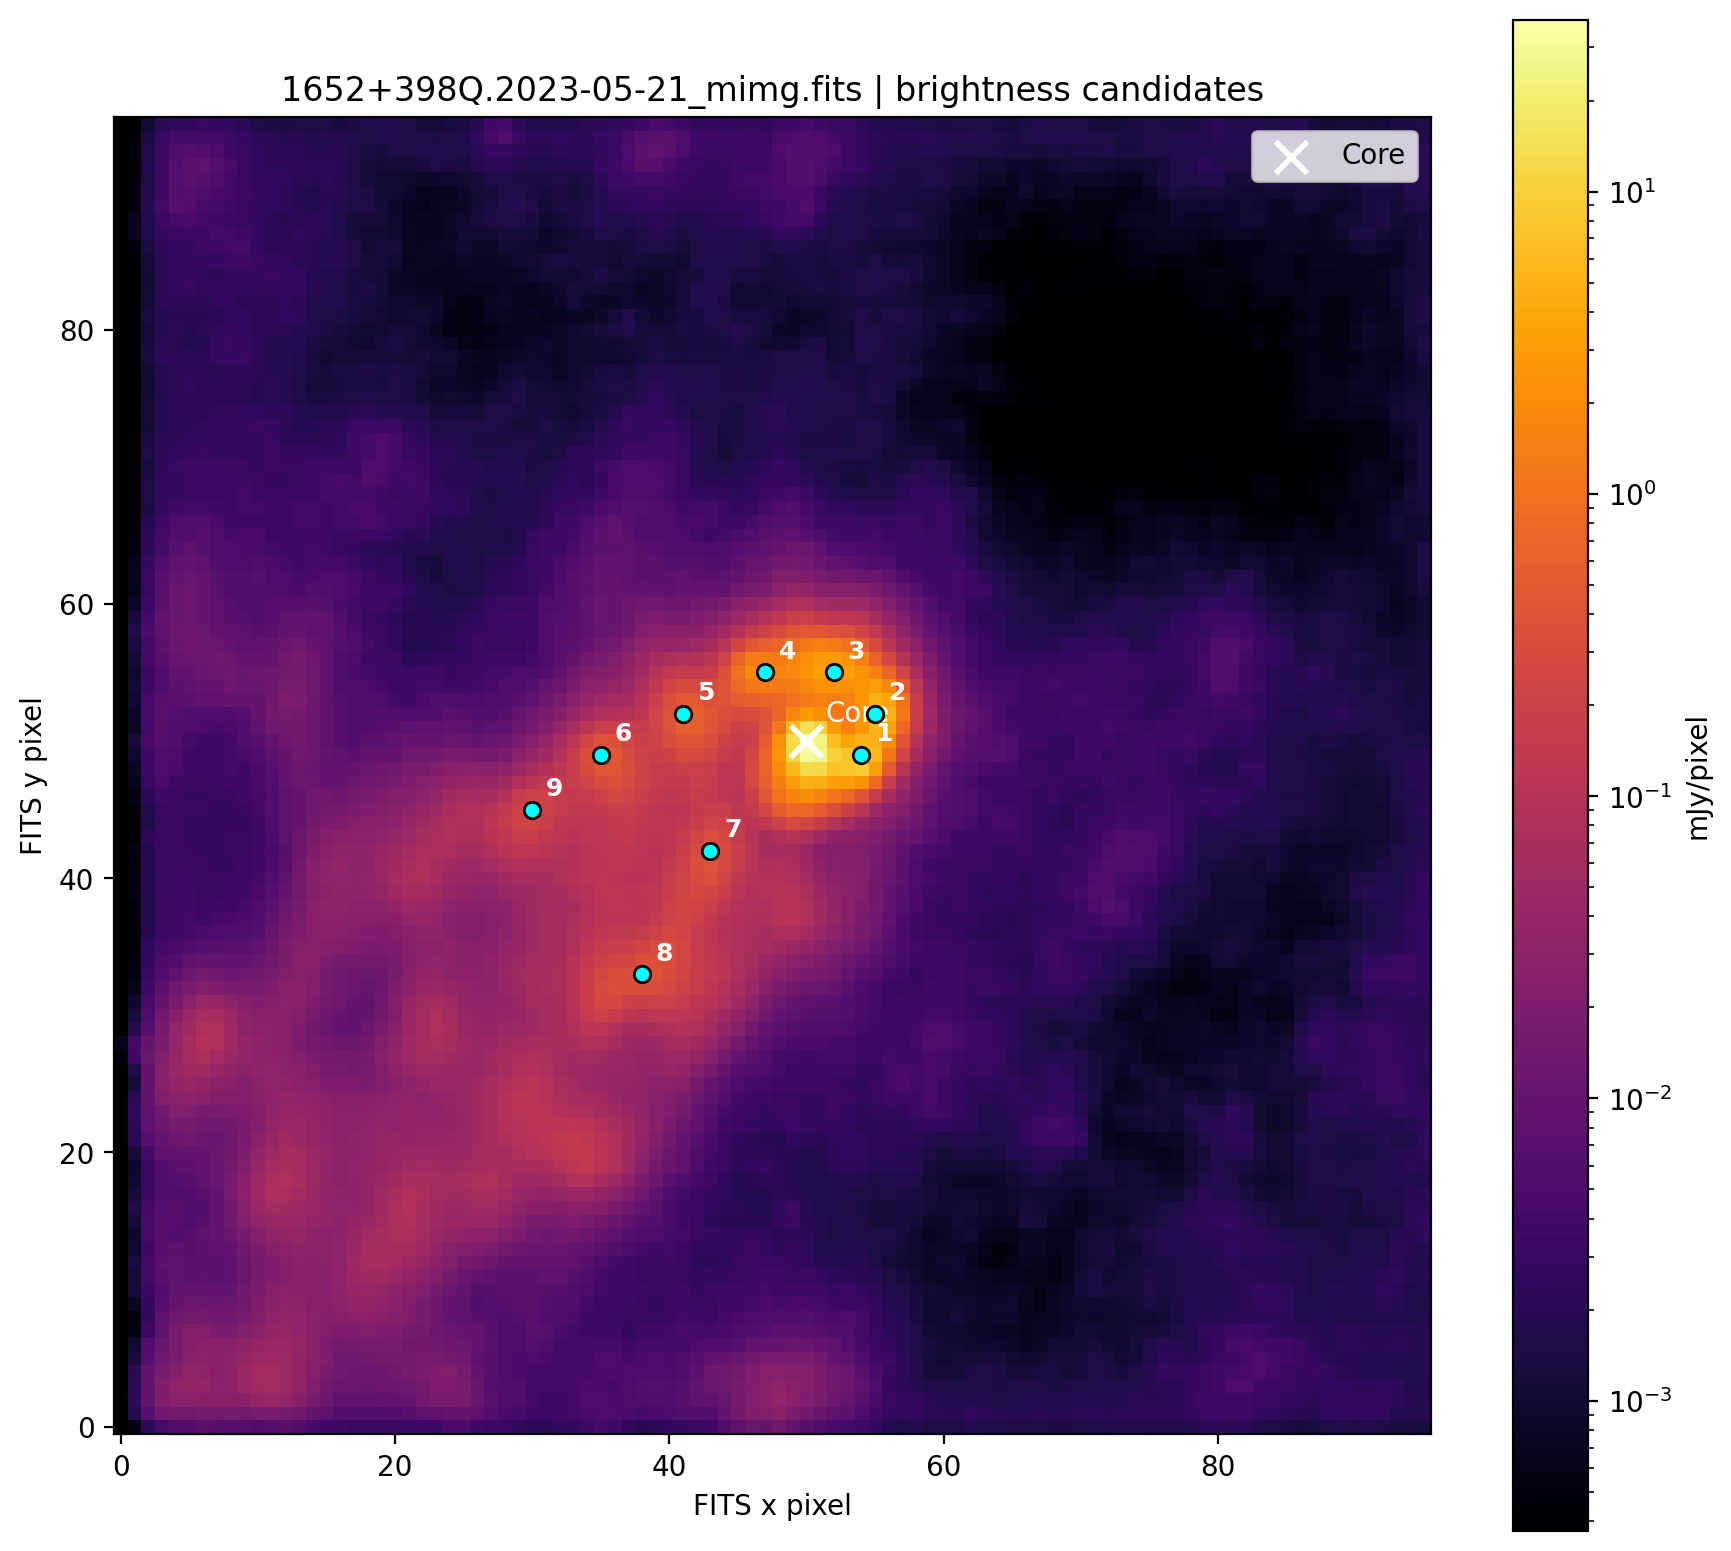

保存先フォルダ: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/jet_tracking_2


In [156]:
# ============================================================
# 手順1：候補点の図とCSVを保存し、図をここに表示
# このセルまで上から順に実行する
# ============================================================
main(mode="candidates")


In [158]:
# ============================================================
# 手順2：上に表示された候補図を見て番号を指定
# コアに近い順など、結びたい順番で記入する
# 例: JET1_IDS = [4, 5, 12]、JET2_IDS = [1, 3, 2]
# ============================================================
JET1_IDS = [7,8]
JET2_IDS = [1,2,3,4,5,6,9]


IMAP理論RMS: 0.42712 mJy/beam
ビーム面積: 57.434 画素 / beam
画素面積換算: 0.0074366 mJy/pixel
候補の下限: 0.14873 mJy/pixel (20倍)
保存: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/jet_tracking_2/2023-05-21_jet_lines_no_numbers.png
保存: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/jet_tracking_2/02_selected_jet_points/2023-05-21.csv
保存: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/jet_tracking_2/03_jet_segment_angles/2023-05-21.csv


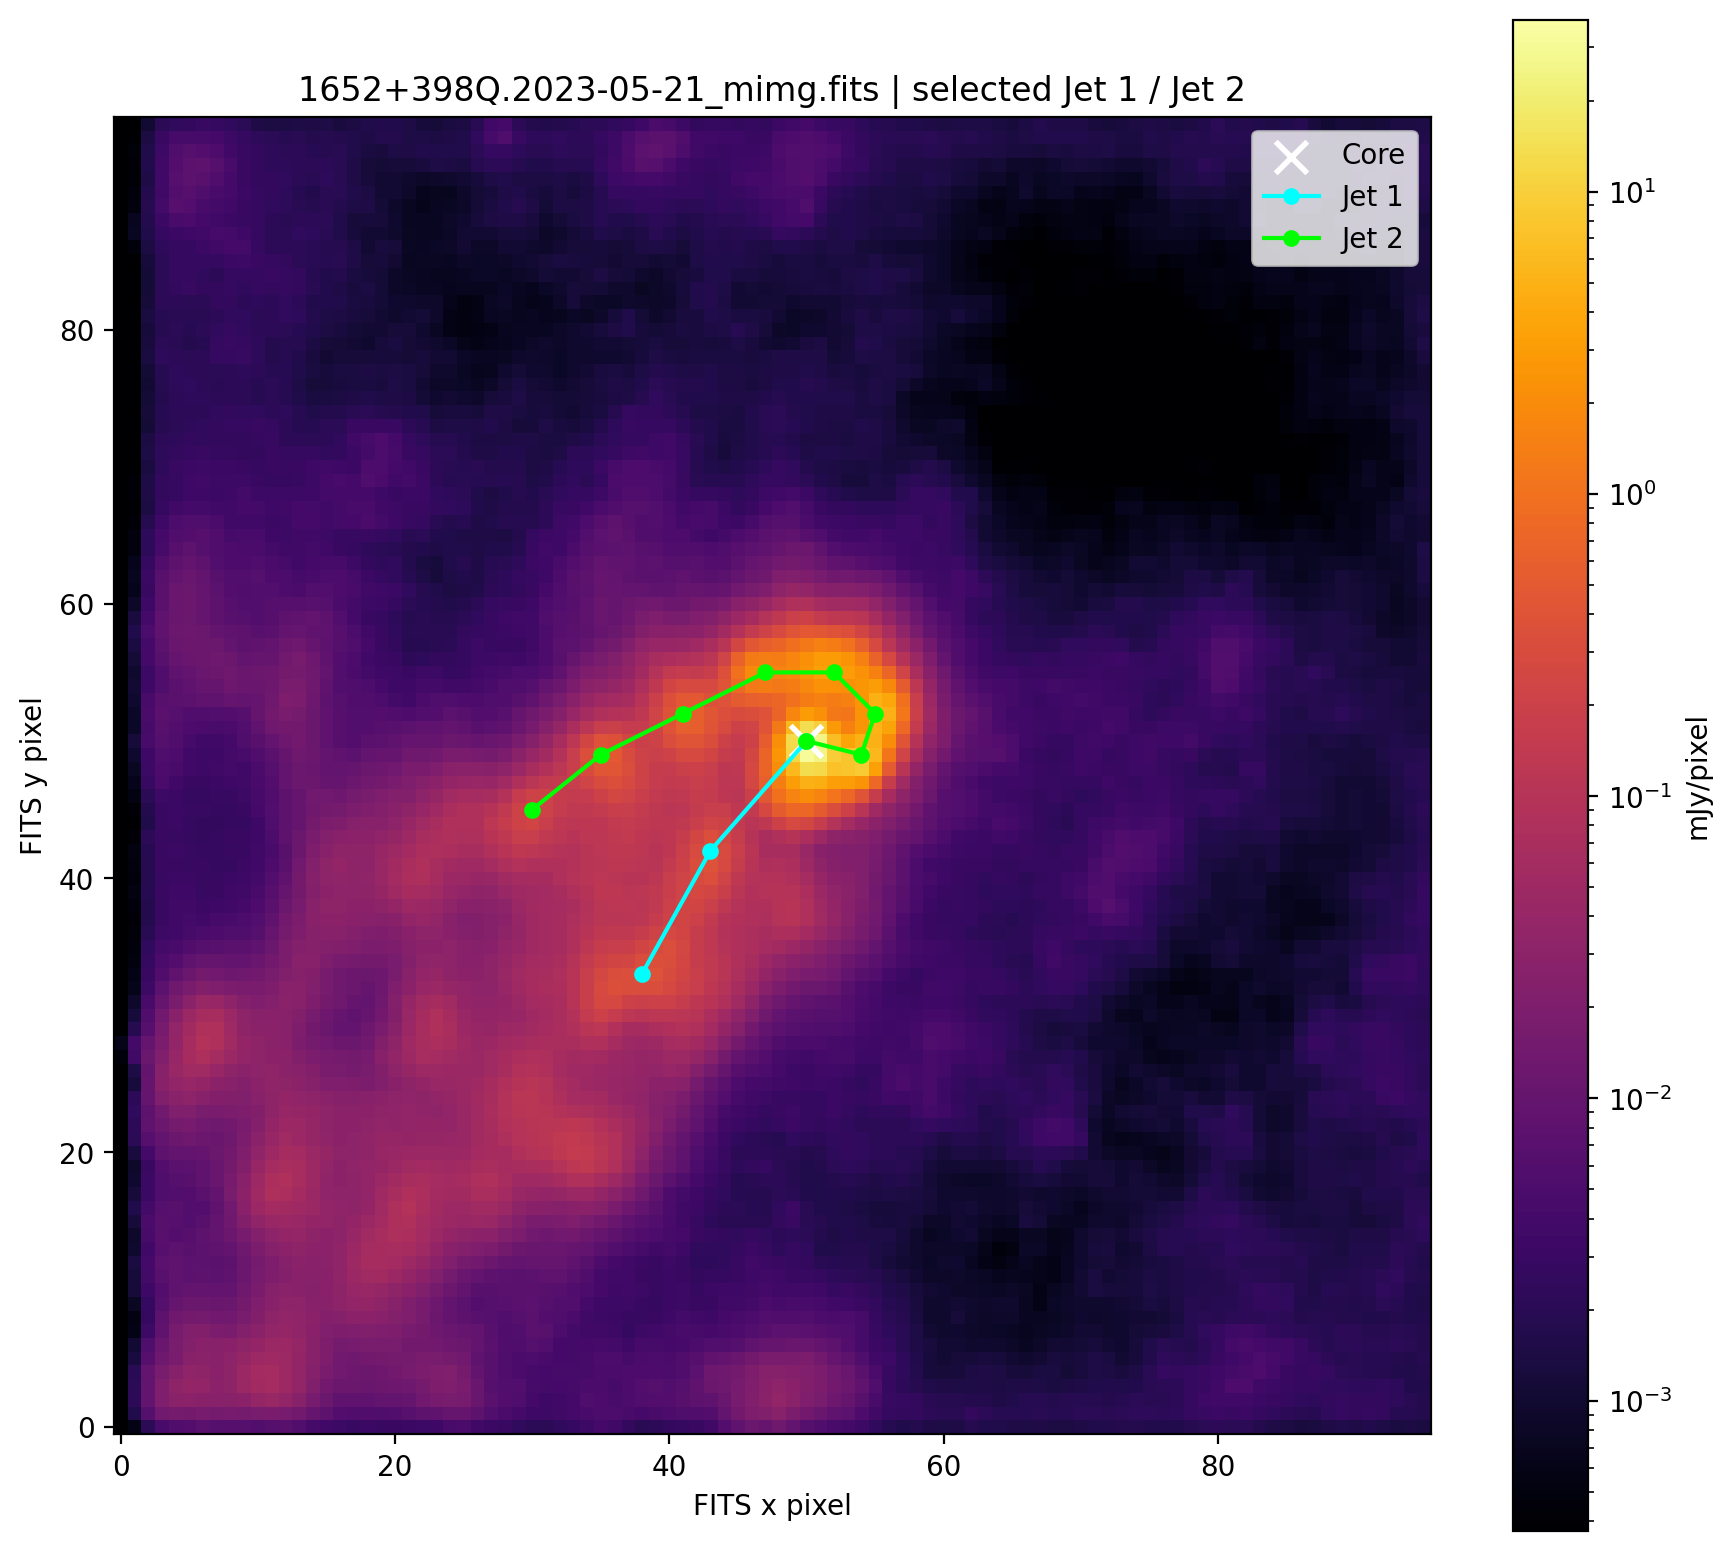

保存先フォルダ: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/jet_tracking_2


In [160]:
# ============================================================
# 手順3：指定した候補を結んだ画像とCSVを保存・表示
# 番号を変えたら手順2とこのセルだけを再実行する
# ============================================================
if JET1_IDS or JET2_IDS:
    main(mode="selected")
else:
    print("手順2に候補番号を入力してから、このセルを実行してください")


輝度と距離のグラフを保存: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/jet_tracking_2/2023-05-21_jet_brightness_vs_distance.png


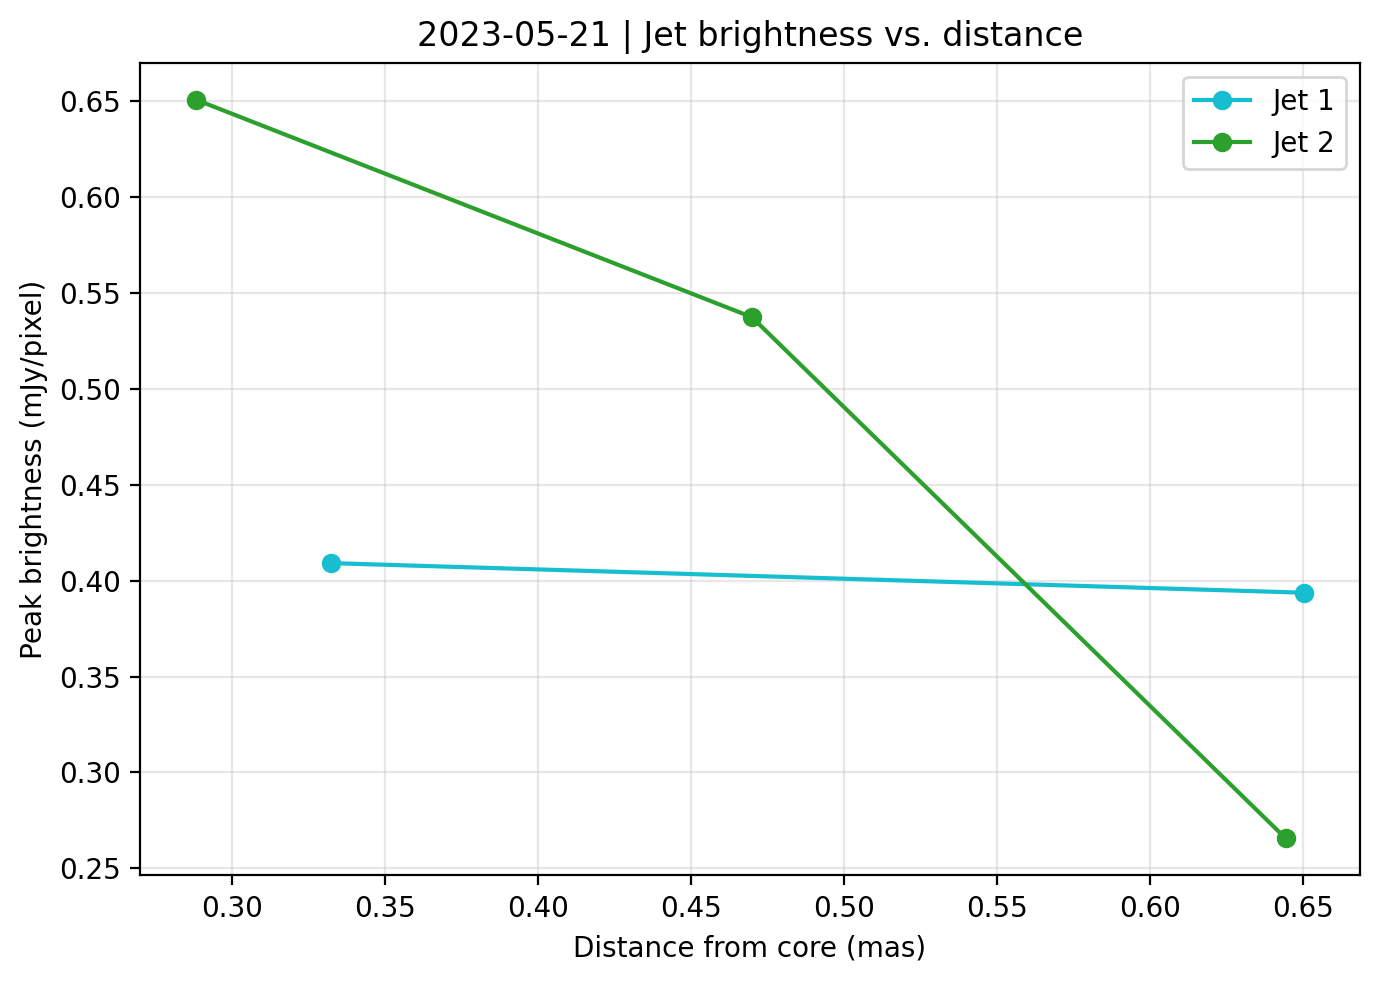

In [162]:
# ============================================================
# 手順4：選択したJet 1・Jet 2の距離とピーク輝度をグラフ化
# 横軸：コアから各候補点までの距離 [mas]
# 縦軸：選択した画素のピーク輝度 [mJy/pixel]
# 手順3で保存したCSVから読み込み、画像を保存して表示する
# ============================================================
if not (JET1_IDS or JET2_IDS):
    print("手順2で候補番号を指定し、手順3を実行してからグラフを作成してください")
else:
    date_match = re.search(r"\d{4}-\d{2}-\d{2}", FITS_FILE.name)
    if date_match is None:
        raise ValueError(f"FITSのファイル名から観測日を読み取れません: {FITS_FILE.name}")
    observation_date = date_match.group()
    selected_csv = OUTPUT_DIR / "02_selected_jet_points" / f"{observation_date}.csv"
    if not selected_csv.is_file():
        raise FileNotFoundError(f"先に手順3を実行してください: {selected_csv}")

    with selected_csv.open("r", newline="", encoding="utf-8-sig") as f:
        selected_rows = list(csv.DictReader(f))

    expected_ids = {"Jet 1": JET1_IDS, "Jet 2": JET2_IDS}
    for jet_name, ids in expected_ids.items():
        csv_ids = [int(row["candidate_id"]) for row in selected_rows if row["jet"] == jet_name]
        if csv_ids != ids:
            raise ValueError(f"{jet_name}の番号がCSVと一致しません。手順3を再実行してください")

    MIN_DISTANCE_MAS = 0.2  # この距離よりコアに近い点はグラフに載せない
    
    fig, ax = plt.subplots(figsize=(7, 5))
    jet_colors = {"Jet 1": "tab:cyan", "Jet 2": "tab:green"}
    for jet_name in ("Jet 1", "Jet 2"):
        jet_rows = sorted(
            (row for row in selected_rows if row["jet"] == jet_name),
            key=lambda row: int(row["order"]),
        )

        jet_rows = [
    row for row in jet_rows
    if float(row["core_distance_mas"]) >= MIN_DISTANCE_MAS
        ]
        if not jet_rows:
            continue
        distance_mas = [float(row["core_distance_mas"]) for row in jet_rows]
        brightness_mjy_pixel = [float(row["peak_brightness_mJy_per_pixel"]) for row in jet_rows]
        ax.plot(distance_mas, brightness_mjy_pixel, "-o", color=jet_colors[jet_name],
                linewidth=1.5, markersize=6, label=jet_name)

    ax.set_xlabel("Distance from core (mas)")
    ax.set_ylabel("Peak brightness (mJy/pixel)")
    ax.set_title(f"{observation_date} | Jet brightness vs. distance")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    graph_png = OUTPUT_DIR / f"{observation_date}_jet_brightness_vs_distance.png"
    fig.savefig(graph_png, dpi=200, bbox_inches="tight")
    plt.close(fig)
    print(f"輝度と距離のグラフを保存: {graph_png.resolve()}")
    display(Image(filename=str(graph_png), width=700))
